In [113]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.cross_decomposition import PLSRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.decomposition import KernelPCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
import seaborn as sns
from scipy.interpolate import interp1d
import statsmodels.api as sm
import statsmodels.formula.api as smf
#import ot

In [114]:
local_path = '/Users/eochoa/Documents/Research_Abuj/'
path_flopp = local_path + 'M4AM/spectral_libraries/FLOPP_and_FLOPP-e/FLOPP.csv/'
path_flopp_e = local_path + 'M4AM/spectral_libraries/FLOPP_and_FLOPP-e/FLOPP-e.csv/'

path_slopp = local_path + 'M4AM/spectral_libraries/SLoPP_and_SLoPP-E/SLoPP/'
path_slopp_e = local_path + 'M4AM/spectral_libraries/SLoPP_and_SLoPP-E/SLoPP-E/'

files_flopp = os.listdir(path=path_flopp)
files_flopp_e = os.listdir(path=path_flopp_e)

directories_slopp = os.listdir(path=path_slopp)
directories_slopp_e = os.listdir(path=path_slopp_e)

In [115]:
polymer_short_names = ['PEVA',
                          'Nylon',
                          'PVC',
                          'PE',
                          'PET',
                          'PLA',
                          'PS',
                          'Acrylic',
                          'Cotton',
                          'Polyester',
                          'ABS',
                          'PU',
                          'PEA',
                          'SBR',
                          'PC',
                          'PP',
                          'PA',
                          'PMMA',
                          'PVA',
                          'PBT']
  
polymer_names = ['Polyethylene Vinyl Acetate',
                    'Nylon',
                    'Polyvinyl Chloride', 
                    'Polyethylene', 
                    'Polyethylene Terephthalate', 
                    'Polylactic acid', 
                    'Polystyrene', 
                    'Acrylic', 
                    'Cotton', 
                    'Polyester', 
                    'Acrylonitrile Butadiene Styrene', 
                    'Polyurethane', 
                    'Polyethylene Adipate', 
                    'Styrene Butadiene Rubber', 
                    'Polycarbonate', 
                    'Polypropylene',
                    'Polyamide',
                    'Polymethyl Methacrylate',
                    'Polyvinyl Acetate',
                    'Polybutylene Terephthalate']

dict_pol_names = pd.DataFrame({'pol_short_names':polymer_short_names, 'polymer':polymer_names})


polymer_short_names_e = ['PVC',
                         'PE',
                         'PET',
                         'ABS',
                         'PU',
                         'PC',
                         'Cotton',
                         'PMMA',
                         'CA',
                         'EAA',
                         'SR',
                         'EVA',
                         'PS',
                         'PA',
                         'PP'] #list(set([x.split(' ', 1)[0] for x in files_flopp]))                      

polymer_names_e = ['Polyvinyl Chloride',
                   'Polyethylene', 
                   'Polyethylene Terephthalate', 
                   'Acrylonitrile Butadiene Styrene', 
                   'Polyurethane',
                   'Polycarbonate', 
                   'Cotton',
                   'Polymethyl Methacrylate',
                   'Cellulose Acetate',
                   'Ethylene Acrylic Acid',
                   'SR',
                   'Polyethylene Vinyl Acetate', 
                   'Polystyrene',
                   'Polyamide',
                   'Polypropylene']

dict_pol_names_e = pd.DataFrame({'pol_short_names':polymer_short_names_e, 'polymer':polymer_names_e})

In [131]:
df_list = list()
for f in files_flopp_e:
    df = pd.read_csv(path_flopp_e + f, sep = ',', header=None)
    df.insert(2, "file_name", [f]*len(df), True) 
    df_list.append(df)
    
df_flopp_e = pd.concat(df_list) 
df_flopp_e

,0,1,file_name
0,399.2094,0.00000,PS 10. Clear Film.CSV
1,401.1380,0.00000,PS 10. Clear Film.CSV
2,403.0665,0.00000,PS 10. Clear Film.CSV
3,404.9951,0.00000,PS 10. Clear Film.CSV
4,406.9236,0.00000,PS 10. Clear Film.CSV
...,...,...,...
1864,3994.0230,98.75421,PP 1. White Fragment.CSV
1865,3995.9510,98.75304,PP 1. White Fragment.CSV
1866,3997.8800,98.74514,PP 1. White Fragment.CSV
1867,3999.8090,98.75369,PP 1. White Fragment.CSV


In [118]:
dict_pol_names
nylon - 16
7 poly acryl

,pol_short_names,polymer
0,PEVA,Polyethylene Vinyl Acetate
1,Nylon,Nylon
2,PVC,Polyvinyl Chloride
3,PE,Polyethylene
4,PET,Polyethylene Terephthalate
5,PLA,Polylactic acid
6,PS,Polystyrene
7,Acrylic,Acrylic
8,Cotton,Cotton
9,Polyester,Polyester


In [117]:
dict_pol_names_e

,pol_short_names,polymer
0,PVC,Polyvinyl Chloride
1,PE,Polyethylene
2,PET,Polyethylene Terephthalate
3,ABS,Acrylonitrile Butadiene Styrene
4,PU,Polyurethane
5,PC,Polycarbonate
6,Cotton,Cotton
7,PMMA,Polymethyl Methacrylate
8,CA,Cellulose Acetate
9,EAA,Ethylene Acrylic Acid


In [133]:
#df_flopp_e.query('polymer == "SR"')

In [130]:
df_slopp.iloc[:,3:4].drop_duplicates()

,polymer
0,Polyethylene
0,Polyethylene Vinyl Acetate
0,Polyvinyl Chloride
0,Polyamide
0,Acrylonitrile Butadiene Styrene
0,Polymethyl Methacrylate
0,Polycarbonate
0,Polyester
0,Cotton
0,Polypropylene


In [119]:
df_list = list()
for f in files_flopp:
    df = pd.read_csv(path_flopp + f, sep = ',', header=None)
    df.insert(2, "file_name", [f]*len(df), True) 
    df_list.append(df)
    
df_flopp = pd.concat(df_list) 
df_flopp.columns = ['wavelength', 'intensity', 'file_name']

df_flopp['pol_short_names'] = [x.split(' ', 1)[0] for x in df_flopp['file_name']]
df_flopp = df_flopp.merge(dict_pol_names, 
               on='pol_short_names').drop(columns=['pol_short_names'])

df_flopp_split_fn = [x.split() for x in df_flopp['file_name']]
df_flopp['color'] = [x[2] if len(x)>2 else '' for x in df_flopp_split_fn]
df_flopp.to_csv('df_flopp.csv')

In [120]:
df_list = list()
for f in files_flopp_e:
    df = pd.read_csv(path_flopp_e + f, sep = ',', header=None)
    df.insert(2, "file_name", [f]*len(df), True) 
    df_list.append(df)
    
df_flopp_e = pd.concat(df_list) 
df_flopp_e.columns = ['wavelength', 'intensity', 'file_name']

df_flopp_e['pol_short_names'] = [x.split()[0] if x.split()[0][-1] != '.'
                                 else 'Cotton' for x in df_flopp_e['file_name']]
df_flopp_e = df_flopp_e.merge(dict_pol_names_e, 
               on='pol_short_names').drop(columns=['pol_short_names'])

df_flopp_split_fn_e = [x.split() for x in df_flopp_e['file_name']]
#df_flopp_e['color'] = [x[2] if len(x)>2 else '' for x in df_flopp_split_fn_e]

color_flopp_e_list = list()
for x in df_flopp_split_fn_e:
    if len(x)>2:
        if x[2] == 'Fiber.CSV' or x[2] == 'Fiber':
            color_flopp_e_list.append(x[1])
        else:
            color_flopp_e_list.append(x[2])
    else:
        color_flopp_e_list.append('')

df_flopp_e['color'] = color_flopp_e_list
df_flopp_e.to_csv('df_flopp_e.csv')

In [121]:
df_list = list()
for d in directories_slopp:
    if os.path.isdir(path_slopp + d):
        directories_slopp_2 = os.listdir(path=path_slopp + d)
        file_list = [x for x in directories_slopp_2 if x[-3:] == 'txt']
        
        for i, x in enumerate(file_list):
            df = pd.read_csv(path_slopp + 
                                     d + 
                                     '/' + 
                                     x, 
                                     sep = '\t', 
                                     header=None)
            df.insert(2, "polymer", [d]*len(df), True)
            df.insert(3, "file_name", [x]*len(df), True)
            df_list.append(df)
    
df_slopp = pd.concat(df_list)
df_slopp.columns = ['wavelength', 'intensity', 'polymer', 'file_name']
df_slopp = df_slopp.loc[:, ['wavelength', 'intensity', 'file_name', 'polymer']]

df_slopp_split_fn = [x.split() for x in df_slopp['file_name']]
df_slopp['color'] = [x[3] if x[2][-1:] == '.' 
     else x[4] if x[2] == 'Acetate'
     else x[2] + " " + x[3] if x[2] == 'Dark' 
     else x[4] + " " + x[5] if x[2] == 'Styrene' and x[4] == 'Light'
     else x[4] + " " + x[5] if x[2] == 'Styrene' and x[4] == 'Dark'
     else x[4] if x[2] == 'Styrene'
     else x[2] for x in df_slopp_split_fn]

df_slopp.to_csv('df_slopp.csv')

In [122]:
df_list = list()
for d in directories_slopp_e:
    if os.path.isdir(path_slopp_e + d):
        directories_slopp_e_2 = os.listdir(path=path_slopp_e + d)
        file_list = [x for x in directories_slopp_e_2 if x[-3:] == 'txt']
        
        for i, x in enumerate(file_list):
            df = pd.read_csv(path_slopp_e + 
                                     d + 
                                     '/' + 
                                     x, 
                                     sep = '\t', 
                                     header=None)
            df.insert(2, "polymer", [d]*len(df), True)
            df.insert(3, "file_name", [x]*len(df), True)
            df_list.append(df)
    
df_slopp_e = pd.concat(df_list)
df_slopp_e.columns = ['wavelength', 'intensity', 'polymer', 'file_name']
df_slopp_e = df_slopp_e.loc[:, ['wavelength', 'intensity', 'file_name', 'polymer']]

df_slopp_e_split_fn = [x.split() for x in df_slopp_e['file_name']]
df_slopp_e['color'] = [x[3] if x[2][-1:] == '.' 
     else x[2] + " " + x[3] if x[2] == 'Dark'
     else x[2] + " " + x[3] if x[2] == 'Light'
     else x[4] if x[2] == 'Styrene'                        
     #else x[4] + " " + x[5] if x[2] == 'Styrene' and x[4] == 'Light'
     #else x[4] + " " + x[5] if x[2] == 'Styrene' and x[4] == 'Dark'
     else x[2] for x in df_slopp_e_split_fn]

df_slopp_e.to_csv('df_slopp_e.csv')

In [123]:
df_flopp_pivot = df_flopp.pivot(index=['file_name', 'polymer', 'color'], 
               columns='wavelength', 
               values='intensity').reset_index()

df_flopp_pivot.columns = list(df_flopp_pivot.columns[:3]) + ['wl_' + str(round(x*100)) for x in df_flopp_pivot.columns[3:]]

In [124]:
df_flopp_pivot_color = pd.get_dummies(data=df_flopp_pivot.iloc[:,2:], drop_first=True)
#df_flopp_pivot_poly = pd.get_dummies(data=df_flopp_pivot.drop(['file_name', 'color'], axis=1), drop_first=True)

In [125]:
df_flopp_pivot_e = df_flopp_e.pivot(index=['file_name', 'polymer', 'color'], 
               columns='wavelength', 
               values='intensity').reset_index()

df_flopp_pivot_e.columns = list(df_flopp_pivot_e.columns[:3]) + ['wl_' + str(round(x*100)) for x in df_flopp_pivot_e.columns[3:]]

In [18]:
df_flopp_pivot_color_e = pd.get_dummies(data=df_flopp_pivot_e.iloc[:,2:], drop_first=True)
#df_flopp_pivot_poly = pd.get_dummies(data=df_flopp_pivot.drop(['file_name', 'color'], axis=1), drop_first=True)

In [19]:
ds = train_test_split(df_flopp_pivot.iloc[:,3:], #df_flopp_pivot_color, 
                      df_flopp_pivot.iloc[:,1], 
                      test_size=0.20, 
                      random_state=42)

X_train, X_test, y_train, y_test = ds

In [20]:
ds_e = train_test_split(df_flopp_pivot_e.iloc[:,3:], #df_flopp_pivot_color, 
                      df_flopp_pivot_e.iloc[:,1], 
                      test_size=0.20, 
                      random_state=42)

X_e_train, X_e_test, y_e_train, y_e_test = ds_e

X_e, y_e = df_flopp_pivot_e.iloc[:,3:], df_flopp_pivot_e.iloc[:,1]

# Flopp

## Logistic Regression

In [31]:
clf = LogisticRegression(random_state=52).fit(X_train, y_train) # 80 / 20
clf.score(X_test, y_test)

/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8421052631578947

In [32]:
y_test_hat = clf.predict(X_test)

y_train_df = pd.DataFrame(y_train)
y_train_df['count'] = 1
classes_count_train = y_train_df.groupby('polymer').count()

pred_test = pd.DataFrame({'true_poly': np.asarray(y_test), 
                          'correct_class':y_test_hat == np.asarray(y_test)})

pred_test_table = pd.concat([classes_count_train,
           pred_test.groupby('true_poly').count(),
           pred_test.groupby('true_poly').mean()], axis=1)

pred_test_table.columns = ['count_train', 'count_test', 'accurasy_test']
pred_test_table

,count_train,count_test,accurasy_test
Acrylic,2,4.0,0.500000
Acrylonitrile butadiene styrene,13,1.0,1.000000
Cotton,11,3.0,1.000000
Nylon,9,3.0,1.000000
Polycarbonates,8,NaN,NaN
Polyester,10,4.0,0.500000
Polyethylene,15,3.0,1.000000
Polyethylene Vinyl Acetate,10,NaN,NaN
Polyethylene adipate,1,NaN,NaN
Polyethylene terephthalate,9,2.0,0.500000


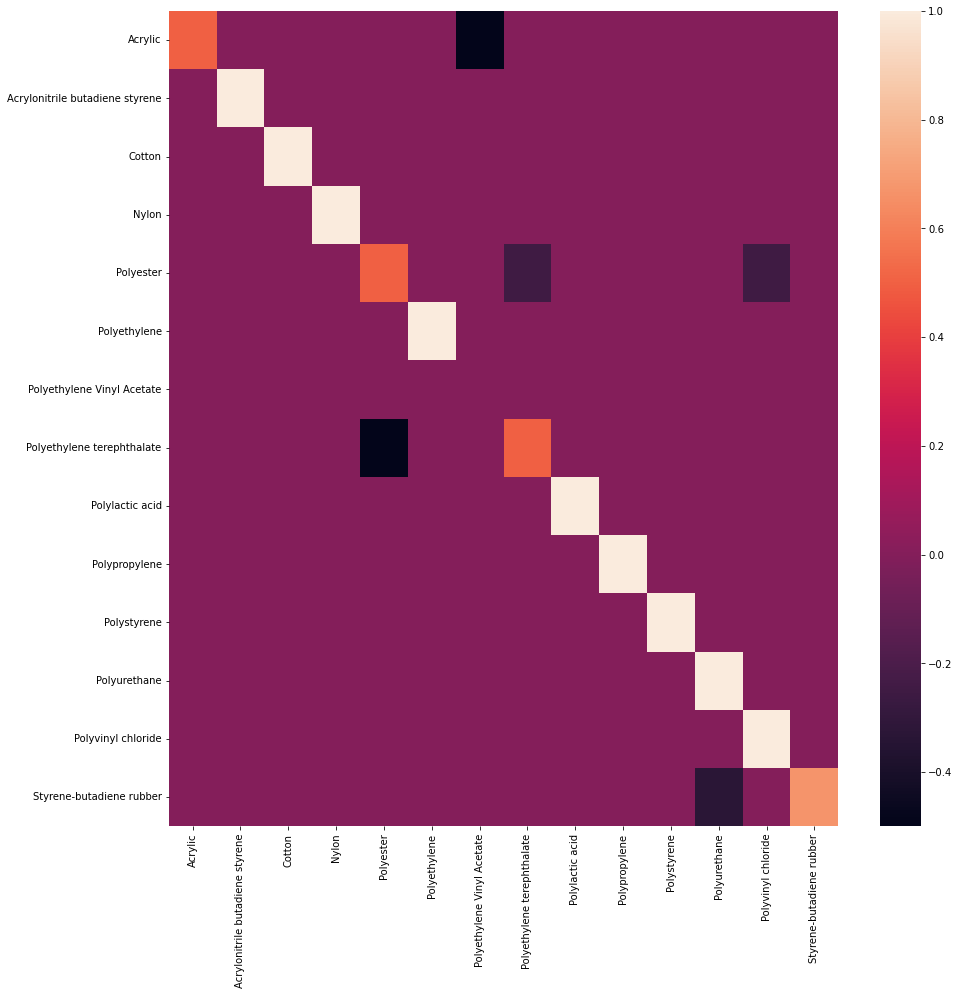

In [33]:
set_classes = set(y_test)
set_classes = set_classes.union(set(y_test_hat))
classes_test_hat = np.array(list(set_classes))
classes_test_hat.sort()

conf_mat = confusion_matrix(y_test, y_test_hat, labels=classes_test_hat)
row_sums = conf_mat.sum(axis=1)
row_sums[row_sums == 0] = 1
conf_mat = conf_mat / row_sums[:, np.newaxis]
conf_mat = 2*np.diag(np.diag(conf_mat)) - conf_mat

conf_mat_df = pd.DataFrame(conf_mat)
conf_mat_df.columns = classes_test_hat
conf_mat_df.index = classes_test_hat


fig, ax = plt.subplots(figsize=(15,15))    
sns.heatmap(conf_mat_df); #, xticklabels=True, yticklabels=True

In [39]:
clf = LogisticRegression(random_state=55).fit(X_train, y_train)
clf.score(X_e, y_e)

/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.6615384615384615

In [40]:
y_e_hat = clf.predict(X_e)

y_train_df = pd.DataFrame(y_train)
y_train_df['count'] = 1
classes_count_train = y_train_df.groupby('polymer').count()

pred_e = pd.DataFrame({'true_poly': np.asarray(y_e), 
                          'correct_class':y_e_hat == np.asarray(y_e)})

pred_e_table = pd.concat([classes_count_train,
           pred_e.groupby('true_poly').count(),
           pred_e.groupby('true_poly').mean()], axis=1)

pred_e_table.columns = ['count_train', 'count_test', 'accurasy_test']
pred_e_table

,count_train,count_test,accurasy_test
Acrylic,2.0,NaN,NaN
Acrylonitrile butadiene styrene,13.0,1.0,1.000000
Cotton,11.0,12.0,0.916667
Nylon,9.0,NaN,NaN
Polycarbonates,8.0,1.0,1.000000
Polyester,10.0,NaN,NaN
Polyethylene,15.0,49.0,0.755102
Polyethylene Vinyl Acetate,10.0,5.0,0.400000
Polyethylene adipate,1.0,NaN,NaN
Polyethylene terephthalate,9.0,22.0,0.727273


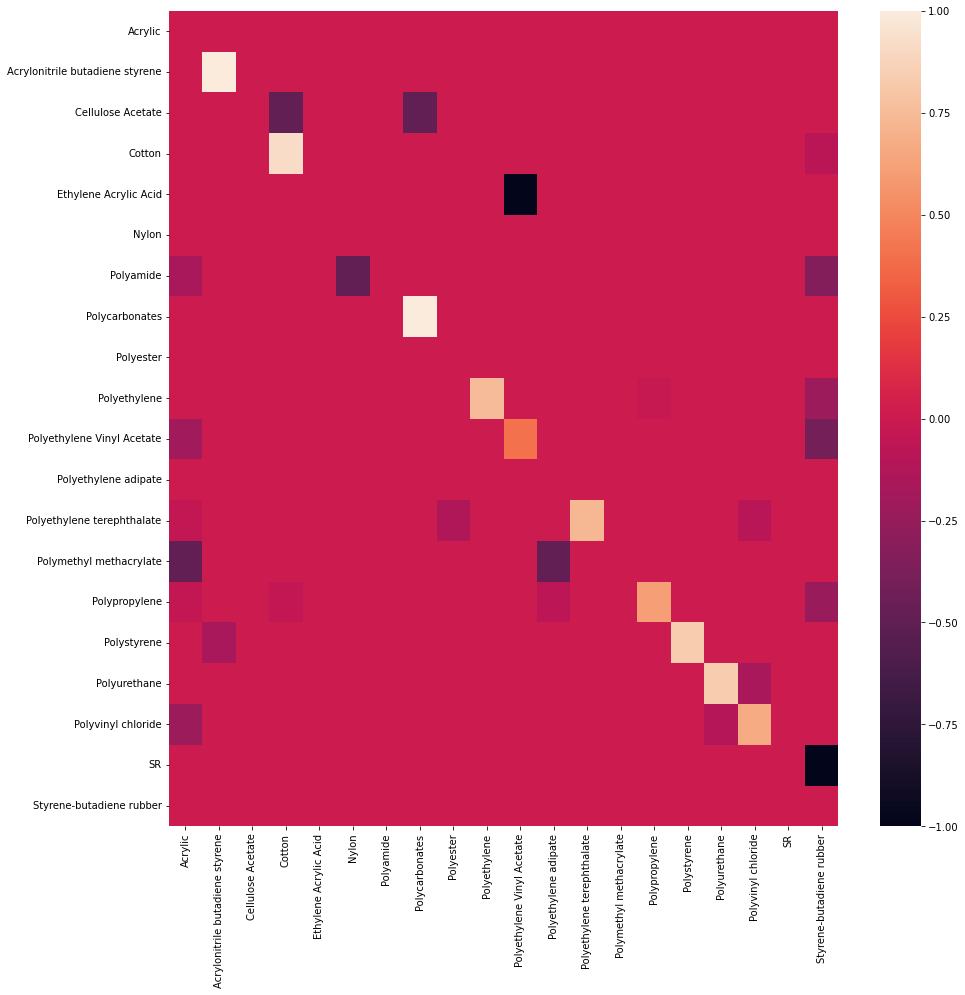

In [41]:
set_classes = set(y_e)
set_classes = set_classes.union(set(y_e_hat))
classes_e_hat = np.array(list(set_classes))
classes_e_hat.sort()

conf_mat = confusion_matrix(y_e, y_e_hat, labels=classes_e_hat)
row_sums = conf_mat.sum(axis=1)
row_sums[row_sums == 0] = 1
conf_mat = conf_mat / row_sums[:, np.newaxis]
conf_mat = 2*np.diag(np.diag(conf_mat)) - conf_mat

conf_mat_df = pd.DataFrame(conf_mat)
conf_mat_df.columns = classes_e_hat
conf_mat_df.index = classes_e_hat

fig, ax = plt.subplots(figsize=(15,15))    
sns.heatmap(conf_mat_df); #, xticklabels=True, yticklabels=True

### Penalty L2

In [42]:
clf = LogisticRegression(penalty = 'l2', C=.005, random_state=1).fit(X_train, y_train)
clf.score(X_test, y_test)

/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8421052631578947

In [43]:
clf = LogisticRegression(penalty = 'l2', C=.0001, random_state=1).fit(X_train, y_train)
clf.score(X_e, y_e)

/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.7435897435897436

### PCA

In [44]:
scaler = StandardScaler()
X_train_std = pd.DataFrame(scaler.fit_transform(X_train))
X_train_std.columns = X_train.columns

X_test_std = pd.DataFrame(scaler.transform(X_test))
X_test_std.columns = X_test.columns

n_componentes = 20
pca = PCA(n_components=n_componentes)
X_train_pca = pd.DataFrame(pca.fit_transform(X_train_std))
X_test_pca = pd.DataFrame(pca.transform(X_test_std))

clf = LogisticRegression(penalty = 'l2', C=10, random_state=1).fit(X_train_pca, y_train)
clf.score(X_test_pca, y_test)

/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.868421052631579

## K Neighbors

In [45]:
neigh = KNeighborsClassifier(n_neighbors=3)
neigh.fit(X_train, y_train)
neigh.score(X_test, y_test)

0.8157894736842105

## SVM

In [46]:
clf = make_pipeline(StandardScaler(), SVC(gamma='auto', probability=True))
clf.fit(X_train, y_train)
clf.score(X_test, y_test)

0.7105263157894737

# Slopp 

## Construct interpolated data

In [21]:
slopp_file_list = df_slopp['file_name'].drop_duplicates()
df_slopp_min = df_slopp.groupby('file_name').min()
df_slopp_max = df_slopp.groupby('file_name').max()
all_wl = np.linspace(0, 3500, num=1400, endpoint=True)

df_slopp_inter = pd.DataFrame()
for fn in slopp_file_list:
    df_slopp_fn = df_slopp.query('file_name == "' + fn + '"')
    df_lenght = df_slopp_fn.shape[0]    
    min_wl = df_slopp_min.loc[fn, 'wavelength']
    max_wl = df_slopp_max.loc[fn, 'wavelength']
    
    polymer_fn = df_slopp_fn['polymer'][0]

    x = df_slopp_fn.loc[:, 'wavelength']
    y = df_slopp_fn.loc[:, 'intensity']
    f = interp1d(x, y)
    #x_new = np.linspace(min_wl, max_wl, num=df_lenght, endpoint=True)
    x_new = all_wl[np.logical_and(all_wl >= min_wl, all_wl <= max_wl)]
    x_out = all_wl[np.logical_or(all_wl < min_wl, all_wl > max_wl)]
    
    df_slopp_inter = pd.concat([df_slopp_inter, 
                              pd.DataFrame({'wavelength':np.concatenate([x_new, x_out]), 
                                            'intensity':np.concatenate([f(x_new), np.zeros(len(x_out))]) , 
                                            'polymer':[polymer_fn] * 1400 , 
                                            'file_name':[fn] * 1400 })])

In [52]:
df_spectr = df_slopp
id_spetr='file_name'

spectr_list = df_spectr[id_spetr].drop_duplicates()
    
df_spectr_min = df_spectr.groupby('file_name').min()
df_spectr_max = df_spectr.groupby('file_name').max()
    
df_spectr_mean = df_spectr.groupby('file_name').mean()
df_spectr_sd = df_spectr.groupby('file_name').std()
    
df_spectr_norm = pd.DataFrame()
    
for fn in spectr_list:
            df_spectr_fn = df_spectr.query(id_spetr + ' == @fn')   
            min_norm = df_spectr_min.loc[fn, 'intensity']
            max_norm = df_spectr_max.loc[fn, 'intensity']
            
            df_spectr_fn['intensity'] = (df_spectr_fn['intensity'] - min_norm) / (max_norm - min_norm)
            
            df_spectr_norm = pd.concat([df_spectr_norm, 
                                         df_spectr_fn])


/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_11086/357835548.py:9: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_spectr_mean = df_spectr.groupby('file_name').mean()
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_11086/357835548.py:10: FutureWarning: The default value of numeric_only in DataFrameGroupBy.std is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_spectr_sd = df_spectr.groupby('file_name').std()
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_11086/357835548.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_11086/357835548.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_spectr_fn['intensity'] = (df_spectr_fn['intensity'] - min_norm) / (max_norm - min_norm)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_11086/357835548.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_spectr_fn['intensity'] = (df_spectr_fn['intensity'] - min_norm) / (max_norm - min_norm)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_11086/357835548

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_11086/357835548.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_spectr_fn['intensity'] = (df_spectr_fn['intensity'] - min_norm) / (max_norm - min_norm)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_11086/357835548.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_spectr_fn['intensity'] = (df_spectr_fn['intensity'] - min_norm) / (max_norm - min_norm)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_11086/357835548

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_11086/357835548.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_spectr_fn['intensity'] = (df_spectr_fn['intensity'] - min_norm) / (max_norm - min_norm)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_11086/357835548.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_spectr_fn['intensity'] = (df_spectr_fn['intensity'] - min_norm) / (max_norm - min_norm)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_11086/357835548

In [53]:
df_spectr_norm

,wavelength,intensity,file_name,polymer,color
0,102.732,0.187518,Polyethylene 27. Blue Microbead.txt,Polyethylene,Blue
1,105.761,0.169276,Polyethylene 27. Blue Microbead.txt,Polyethylene,Blue
2,108.788,0.092254,Polyethylene 27. Blue Microbead.txt,Polyethylene,Blue
3,111.814,0.098638,Polyethylene 27. Blue Microbead.txt,Polyethylene,Blue
4,114.839,0.076895,Polyethylene 27. Blue Microbead.txt,Polyethylene,Blue
...,...,...,...,...,...
1341,3490.350,0.030469,Polyethylene Terephthalate 8. Clear Juice Bott...,Polyethylene Terephthalate,Clear
1342,3492.370,0.030167,Polyethylene Terephthalate 8. Clear Juice Bott...,Polyethylene Terephthalate,Clear
1343,3494.390,0.026137,Polyethylene Terephthalate 8. Clear Juice Bott...,Polyethylene Terephthalate,Clear
1344,3496.410,0.032480,Polyethylene Terephthalate 8. Clear Juice Bott...,Polyethylene Terephthalate,Clear


In [104]:
def interpol_spect(df_spectr, min_wl=0, max_wl=3500, n=1400, id_spetr='file_name'):
    
    spectr_list = df_spectr[id_spetr].drop_duplicates()
    df_spectr_min = df_spectr.groupby('file_name').min()
    df_spectr_max = df_spectr.groupby('file_name').max()
    all_wl = np.linspace(min_wl, max_wl, num=n, endpoint=True)

    df_spectr_inter = pd.DataFrame()
    

    for fn in spectr_list:
        df_spectr_fn = df_spectr.query(id_spetr + ' == @fn')
        #df_lenght = df_spectr_fn.shape[0]    
        min_wl = df_spectr_min.loc[fn, 'wavelength']
        max_wl = df_spectr_max.loc[fn, 'wavelength']
        
        polymer_fn = df_spectr_fn['polymer'][0]
    
        x = df_spectr_fn.loc[:, 'wavelength']
        y = df_spectr_fn.loc[:, 'intensity']
        f = interp1d(x, y)
        #x_new = np.linspace(min_wl, max_wl, num=df_lenght, endpoint=True)
        x_new = all_wl[np.logical_and(all_wl >= min_wl, all_wl <= max_wl)]
        x_out = all_wl[np.logical_or(all_wl < min_wl, all_wl > max_wl)]
        
        df_spectr_inter = pd.concat([df_spectr_inter, 
                                  pd.DataFrame({'wavelength':np.concatenate([x_new, x_out]), 
                                                'intensity':np.concatenate([f(x_new), np.zeros(len(x_out))]) , 
                                                'polymer':[polymer_fn] * 1400 , 
                                                'file_name':[fn] * 1400 }).sort_values('wavelength')])
    return df_spectr_inter.reset_index(drop=True)

In [109]:
def norm_spect(df_spectr, norm_type='MINMAX', id_spetr='file_name'):
    
    spectr_list = df_spectr[id_spetr].drop_duplicates()
    
    df_spectr_min = df_spectr.groupby('file_name').min()
    df_spectr_max = df_spectr.groupby('file_name').max()
    
    df_spectr_mean = df_spectr.groupby('file_name').mean()
    df_spectr_sd = df_spectr.groupby('file_name').std()
    
    df_spectr_norm = pd.DataFrame()
    
    
    if norm_type == 'MINMAX':

        for fn in spectr_list:
            df_spectr_fn = df_spectr.query(id_spetr + ' == @fn')   
            min_norm = df_spectr_min.loc[fn, 'intensity']
            max_norm = df_spectr_max.loc[fn, 'intensity']
            
            df_spectr_fn.loc[:,'intensity'] = (df_spectr_fn['intensity'] - min_norm) / (max_norm - min_norm)
            
            df_spectr_norm = pd.concat([df_spectr_norm, 
                                         df_spectr_fn])
        return df_spectr_norm
    
    if norm_type == 'SNV':
    
        for fn in spectr_list:
            df_spectr_fn = df_spectr.query(id_spetr + ' == @fn')
            mean_norm = df_spectr_min.loc[fn, 'intensity']
            sd_norm = df_spectr_max.loc[fn, 'intensity']
            
            df_spectr_fn.loc[:,'intensity'] = (df_spectr_fn['intensity'] - mean_norm) / sd_norm
            
            df_spectr_norm = pd.concat([df_spectr_norm, 
                                         df_spectr_fn])
        return df_spectr_norm.reset_index(drop=True)

In [111]:

df_slopp_int = interpol_spect(df_slopp)
df_slopp_int_norm = norm_spect(df_slopp_int, norm_type = 'SNV')

In [112]:
norm_spect(df_slopp_int, norm_type = 'SNV')

,wavelength,intensity,polymer,file_name
0,0.000000,0.000000,Polyethylene,Polyethylene 27. Blue Microbead.txt
1,2.501787,0.000000,Polyethylene,Polyethylene 27. Blue Microbead.txt
2,5.003574,0.000000,Polyethylene,Polyethylene 27. Blue Microbead.txt
3,7.505361,0.000000,Polyethylene,Polyethylene 27. Blue Microbead.txt
4,10.007148,0.000000,Polyethylene,Polyethylene 27. Blue Microbead.txt
...,...,...,...,...
207195,3489.992852,0.031741,Polyethylene Terephthalate,Polyethylene Terephthalate 8. Clear Juice Bott...
207196,3492.494639,0.031063,Polyethylene Terephthalate,Polyethylene Terephthalate 8. Clear Juice Bott...
207197,3494.996426,0.029115,Polyethylene Terephthalate,Polyethylene Terephthalate 8. Clear Juice Bott...
207198,3497.498213,0.033022,Polyethylene Terephthalate,Polyethylene Terephthalate 8. Clear Juice Bott...


In [102]:
df_slopp_int
#df_slopp_int_norm.query('file_name == "Polyethylene Terephthalate 8. Clear Juice Bottle.txt"')

,index,wavelength,intensity,polymer,file_name
0,757,0.000000,0.000000,Polyethylene,Polyethylene 27. Blue Microbead.txt
1,758,2.501787,0.000000,Polyethylene,Polyethylene 27. Blue Microbead.txt
2,759,5.003574,0.000000,Polyethylene,Polyethylene 27. Blue Microbead.txt
3,760,7.505361,0.000000,Polyethylene,Polyethylene 27. Blue Microbead.txt
4,761,10.007148,0.000000,Polyethylene,Polyethylene 27. Blue Microbead.txt
...,...,...,...,...,...
207195,1354,3489.992852,558.949584,Polyethylene Terephthalate,Polyethylene Terephthalate 8. Clear Juice Bott...
207196,1355,3492.494639,547.014069,Polyethylene Terephthalate,Polyethylene Terephthalate 8. Clear Juice Bott...
207197,1356,3494.996426,512.701959,Polyethylene Terephthalate,Polyethylene Terephthalate 8. Clear Juice Bott...
207198,1357,3497.498213,581.513384,Polyethylene Terephthalate,Polyethylene Terephthalate 8. Clear Juice Bott...


In [80]:
df_slopp

,wavelength,intensity,file_name,polymer,color
0,102.732,178.8150,Polyethylene 27. Blue Microbead.txt,Polyethylene,Blue
1,105.761,161.4190,Polyethylene 27. Blue Microbead.txt,Polyethylene,Blue
2,108.788,87.9718,Polyethylene 27. Blue Microbead.txt,Polyethylene,Blue
3,111.814,94.0597,Polyethylene 27. Blue Microbead.txt,Polyethylene,Blue
4,114.839,73.3256,Polyethylene 27. Blue Microbead.txt,Polyethylene,Blue
...,...,...,...,...,...
1341,3490.350,557.0910,Polyethylene Terephthalate 8. Clear Juice Bott...,Polyethylene Terephthalate,Clear
1342,3492.370,551.5600,Polyethylene Terephthalate 8. Clear Juice Bott...,Polyethylene Terephthalate,Clear
1343,3494.390,477.8850,Polyethylene Terephthalate 8. Clear Juice Bott...,Polyethylene Terephthalate,Clear
1344,3496.410,593.8600,Polyethylene Terephthalate 8. Clear Juice Bott...,Polyethylene Terephthalate,Clear


In [92]:
interpol_spect(df_slopp)

,index,wavelength,intensity,polymer,file_name
0,757,0.000000,0.000000,Polyethylene,Polyethylene 27. Blue Microbead.txt
1,758,2.501787,0.000000,Polyethylene,Polyethylene 27. Blue Microbead.txt
2,759,5.003574,0.000000,Polyethylene,Polyethylene 27. Blue Microbead.txt
3,760,7.505361,0.000000,Polyethylene,Polyethylene 27. Blue Microbead.txt
4,761,10.007148,0.000000,Polyethylene,Polyethylene 27. Blue Microbead.txt
...,...,...,...,...,...
207195,1354,3489.992852,558.949584,Polyethylene Terephthalate,Polyethylene Terephthalate 8. Clear Juice Bott...
207196,1355,3492.494639,547.014069,Polyethylene Terephthalate,Polyethylene Terephthalate 8. Clear Juice Bott...
207197,1356,3494.996426,512.701959,Polyethylene Terephthalate,Polyethylene Terephthalate 8. Clear Juice Bott...
207198,1357,3497.498213,581.513384,Polyethylene Terephthalate,Polyethylene Terephthalate 8. Clear Juice Bott...


In [28]:
df_slopp_inter

,wavelength,intensity,polymer,file_name
0,105.075054,165.358493,Polyethylene,Polyethylene 27. Blue Microbead.txt
1,107.576841,117.359400,Polyethylene,Polyethylene 27. Blue Microbead.txt
2,110.078628,90.568367,Polyethylene,Polyethylene 27. Blue Microbead.txt
3,112.580415,88.806504,Polyethylene,Polyethylene 27. Blue Microbead.txt
4,115.082202,73.630113,Polyethylene,Polyethylene 27. Blue Microbead.txt
...,...,...,...,...
1395,92.566119,0.000000,Polyethylene Terephthalate,Polyethylene Terephthalate 8. Clear Juice Bott...
1396,95.067906,0.000000,Polyethylene Terephthalate,Polyethylene Terephthalate 8. Clear Juice Bott...
1397,97.569693,0.000000,Polyethylene Terephthalate,Polyethylene Terephthalate 8. Clear Juice Bott...
1398,100.071480,0.000000,Polyethylene Terephthalate,Polyethylene Terephthalate 8. Clear Juice Bott...


In [22]:
df_slopp_inter.loc[:, ['wavelength', 'intensity', 'file_name', 'polymer']].to_csv('df_slopp_inter.csv')

In [23]:
slopp_e_file_list = df_slopp_e['file_name'].drop_duplicates()
df_slopp_e_min = df_slopp_e.groupby('file_name').min()
df_slopp_e_max = df_slopp_e.groupby('file_name').max()
all_wl_e = np.linspace(0, 3500, num=1400, endpoint=True)

df_slopp_e_inter = pd.DataFrame()
for fn in slopp_e_file_list:
    df_slopp_e_fn = df_slopp_e.query('file_name == "' + fn + '"')
    df_lenght = df_slopp_fn.shape[0]    
    min_wl = df_slopp_e_min.loc[fn, 'wavelength']
    max_wl = df_slopp_e_max.loc[fn, 'wavelength']
    
    polymer_fn = df_slopp_e_fn['polymer'][0]

    x = df_slopp_e_fn.loc[:, 'wavelength']
    y = df_slopp_e_fn.loc[:, 'intensity']
    f = interp1d(x, y)
    #x_new = np.linspace(min_wl, max_wl, num=df_lenght, endpoint=True)
    x_new = all_wl_e[np.logical_and(all_wl >= min_wl, all_wl <= max_wl)]
    x_out = all_wl_e[np.logical_or(all_wl < min_wl, all_wl > max_wl)]
    
    df_slopp_e_inter = pd.concat([df_slopp_e_inter, 
                              pd.DataFrame({'wavelength':np.concatenate([x_new, x_out]), 
                                            'intensity':np.concatenate([f(x_new), np.zeros(len(x_out))]) , 
                                            'polymer':[polymer_fn] * 1400 , 
                                            'file_name':[fn] * 1400 })])

In [24]:
df_slopp_e_inter.loc[:, ['wavelength', 'intensity', 'file_name', 'polymer']].to_csv('df_slopp_e_inter.csv')

In [48]:
df_slopp_pivot = df_slopp_inter.pivot(index=['file_name', 'polymer'], 
                                      columns='wavelength', 
                                      values='intensity').reset_index()

In [49]:
df_slopp_e_pivot = df_slopp_e_inter.pivot(index=['file_name', 'polymer'], 
                                      columns='wavelength', 
                                      values='intensity').reset_index()

In [50]:
ds = train_test_split(df_slopp_pivot.iloc[:,2:], 
                      df_slopp_pivot.iloc[:,1], 
                      test_size=0.20, 
                      random_state=42)

X_train, X_test, y_train, y_test = ds

In [52]:
ds_e = train_test_split(df_slopp_e_pivot.iloc[:,2:], 
                      df_slopp_e_pivot.iloc[:,1], 
                      test_size=0.20, 
                      random_state=42)

X_e_train, X_e_test, y_e_train, y_e_test = ds_e

X_e, y_e = df_slopp_e_pivot.iloc[:,2:], df_slopp_e_pivot.iloc[:,1]

## Logistic Regression

In [53]:
clf = LogisticRegression(random_state=52).fit(X_train, y_train) # 80 / 20
clf.score(X_test, y_test)

/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/utils/validation.py:1688: FutureWarning: Feature names only support names that are all strings. Got feature names with dtypes: ['float']. An error will be raised in 1.2.
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/utils/validation.py:1688: FutureWarning: Feature names only support names that are all strings. Got feature names wi

0.8

In [54]:
y_test_hat = clf.predict(X_test)

y_train_df = pd.DataFrame(y_train)
y_train_df['count'] = 1
classes_count_train = y_train_df.groupby('polymer').count()

pred_test = pd.DataFrame({'true_poly': np.asarray(y_test), 
                          'correct_class':y_test_hat == np.asarray(y_test)})

pred_test_table = pd.concat([classes_count_train,
           pred_test.groupby('true_poly').count(),
           pred_test.groupby('true_poly').mean()], axis=1)

pred_test_table.columns = ['count_train', 'count_test', 'accurasy_test']
pred_test_table

/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/utils/validation.py:1688: FutureWarning: Feature names only support names that are all strings. Got feature names with dtypes: ['float']. An error will be raised in 1.2.
  warnings.warn(


,count_train,count_test,accurasy_test
Acrylic,9,1.0,1.000000
Acrylonitrile Butadiene Styrene,6,4.0,0.750000
Cellulose Acetate,3,1.0,0.000000
Cotton,11,5.0,1.000000
Polyamide,7,NaN,NaN
Polycarbonate,6,1.0,1.000000
Polyester,9,1.0,0.000000
Polyethylene,17,7.0,1.000000
Polyethylene Terephthalate,8,1.0,1.000000
Polyethylene Vinyl Acetate,5,NaN,NaN


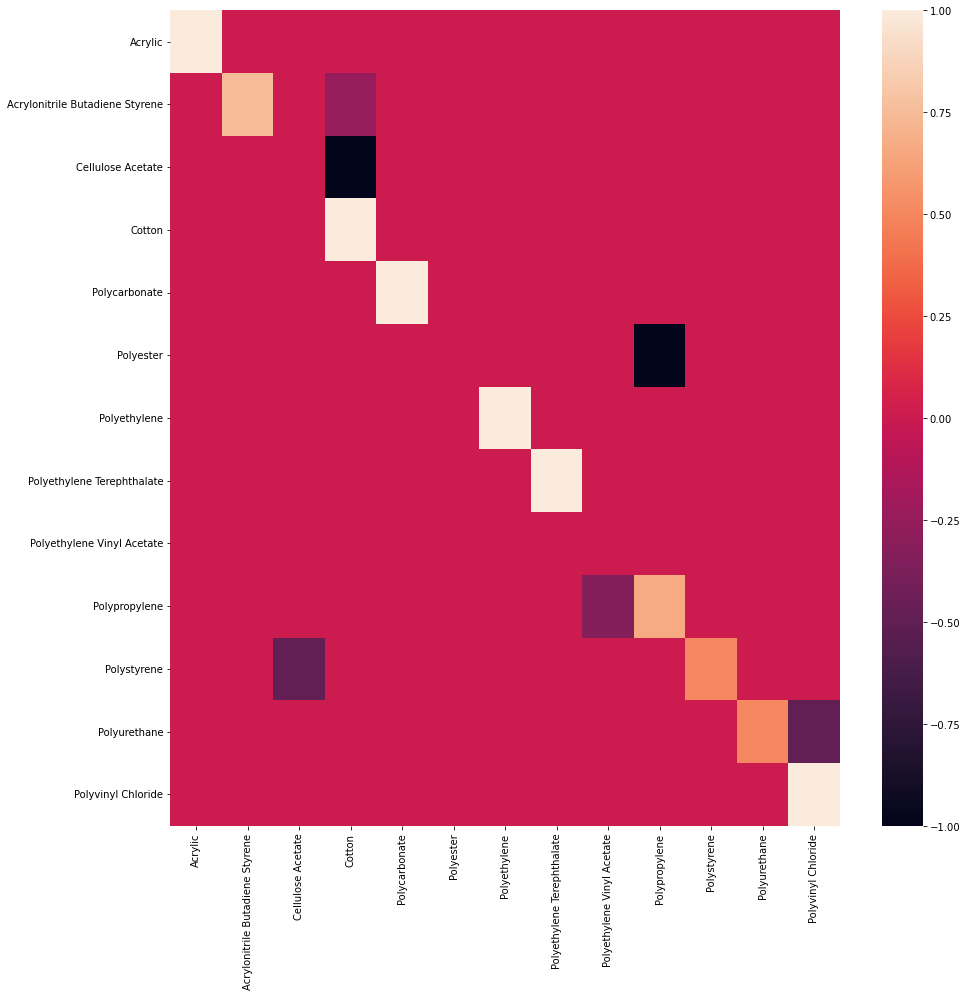

In [55]:
set_classes = set(y_test)
set_classes = set_classes.union(set(y_test_hat))
classes_test_hat = np.array(list(set_classes))
classes_test_hat.sort()

conf_mat = confusion_matrix(y_test, y_test_hat, labels=classes_test_hat)
row_sums = conf_mat.sum(axis=1)
row_sums[row_sums == 0] = 1
conf_mat = conf_mat / row_sums[:, np.newaxis]
conf_mat = 2*np.diag(np.diag(conf_mat)) - conf_mat

conf_mat_df = pd.DataFrame(conf_mat)
conf_mat_df.columns = classes_test_hat
conf_mat_df.index = classes_test_hat


fig, ax = plt.subplots(figsize=(15,15))    
sns.heatmap(conf_mat_df); #, xticklabels=True, yticklabels=True

In [57]:
clf = LogisticRegression(random_state=55).fit(X_train, y_train)
clf.score(X_e, y_e)

/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/utils/validation.py:1688: FutureWarning: Feature names only support names that are all strings. Got feature names with dtypes: ['float']. An error will be raised in 1.2.
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/utils/validation.py:1688: FutureWarning: Feature names only support names that are all strings. Got feature names wi

0.6194690265486725

### Penalty L2

In [58]:
clf = LogisticRegression(penalty = 'l2', C=0.005, random_state=1).fit(X_train, y_train)
clf.score(X_test, y_test)

/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/utils/validation.py:1688: FutureWarning: Feature names only support names that are all strings. Got feature names with dtypes: ['float']. An error will be raised in 1.2.
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/utils/validation.py:1688: FutureWarning: Feature names only support names that are all strings. Got feature names wi

0.8666666666666667

In [59]:
clf = LogisticRegression(penalty = 'l2', C=.0001, random_state=1).fit(X_train, y_train)
clf.score(X_e, y_e)

/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/utils/validation.py:1688: FutureWarning: Feature names only support names that are all strings. Got feature names with dtypes: ['float']. An error will be raised in 1.2.
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/utils/validation.py:1688: FutureWarning: Feature names only support names that are all strings. Got feature names wi

0.6371681415929203

### Penalty PCA

In [60]:
scaler = StandardScaler()
X_train_std = pd.DataFrame(scaler.fit_transform(X_train))
X_train_std.columns = X_train.columns

X_test_std = pd.DataFrame(scaler.transform(X_test))
X_test_std.columns = X_test.columns

n_componentes = 25
pca = PCA(n_components=n_componentes)
X_train_pca = pd.DataFrame(pca.fit_transform(X_train_std))
X_test_pca = pd.DataFrame(pca.transform(X_test_std))

clf = LogisticRegression(penalty = 'l2', C=10, random_state=1).fit(X_train_pca, y_train)
clf.score(X_test_pca, y_test)

/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/utils/validation.py:1688: FutureWarning: Feature names only support names that are all strings. Got feature names with dtypes: ['float']. An error will be raised in 1.2.
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/utils/validation.py:1688: FutureWarning: Feature names only support names that are all strings. Got feature names with dtypes: ['float']. An error will be raised in 1.2.
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/utils/validation.py:1688: FutureWarning: Feature names only support names that are all strings. Got feature names with dtypes: ['float']. An error will be raised in 1.2.
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/STATS507/lib/python3.9/site-packages/sklearn/utils/validation.py:1688: FutureWarning: Feature names only support names that are all strings. Got feature names with dtypes: 

0.8